# Computing Lab 1: eight corrected experiments

Complete Python programs, datasets, explanations and saved outputs.

**Start:** connect to a Python runtime and run the setup and data cells below. Then run any experiment. A CPU runtime is sufficient. To run everything, use **Runtime > Run all**. Optional upload, Drive and download actions are disabled until you enable them.

The three supplied PDF records were references for the programs, not instructions to execute. This notebook covers only the eight experiments requested. Missing CSVs have been supplied from the weather example, scikit-learn and official UCI sources.

Saved outputs come from a fresh **local Python 3.12 kernel**. They do not imply that a live Colab session or its optional Google Drive features were tested. Re-run to obtain results for your runtime. The heart experiment is educational and is not clinically validated.

## Setup: install libraries

Run this first. Internet is required when libraries must be installed. The main algorithm packages are pinned to versions used in validation. In Colab, if an already-imported package is replaced and Colab requests a session restart, restart the session and run from the top again.

In [1]:
import subprocess
import sys

requirements = ['numpy>=1.26,<3', 'pandas>=2.2,<3', 'scikit-learn==1.7.2', 'matplotlib==3.10.7', 'networkx>=3.2,<4', 'pgmpy==1.0.0']
subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "--no-cache-dir",
                "--disable-pip-version-check", *requirements],
               check=True, capture_output=True, text=True)
print("Libraries ready. Python:", sys.version.split()[0])

Libraries ready. Python: 3.12.14


## Data: restore the included CSV files

This cell writes bundled datasets to a dedicated `computing_lab1_workspace` folder and switches to that folder. Re-running it restores the supplied files. The long encoded payload is just compressed dataset content; no remote dataset download is needed.

- Weather: the 14 records in the reference ID3 code.
- Iris and Wine: scikit-learn bundled datasets.
- Heart: [UCI Cleveland](https://archive.ics.uci.edu/dataset/45/heart+disease); original diagnosis 0 is absence and 1-4 map to presence.
- SMS: [UCI SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection), credited to Almeida and Hidalgo.

Full attribution and file checksums are restored under `data`.

In [2]:
import base64
import gzip
import json
import os
from pathlib import Path

LAB_DIR = Path(globals().get("LAB_DIR", Path.cwd() / "computing_lab1_workspace")).resolve()
LAB_DIR.mkdir(parents=True, exist_ok=True)
(LAB_DIR / "data").mkdir(exist_ok=True)
(LAB_DIR / "results").mkdir(exist_ok=True)
DATA_PAYLOAD = (
    '...'
    'ZYFEMz4+/7//+edfsYXCEAI/CwA='
)
assets = json.loads(gzip.decompress(base64.b64decode(DATA_PAYLOAD)))
for name, content in assets.items():
    (LAB_DIR / "data" / name).write_bytes(base64.b64decode(content))
os.chdir(LAB_DIR)
print("Working folder:", LAB_DIR)
print("CSV files:", sorted(p.name for p in (LAB_DIR / "data").glob("*.csv")))


Working folder: /Users/suhathalib/Documents/ChatGPT/Mtech/tmp/computing_lab_review/notebook_run/computing_lab1_workspace
CSV files: ['heart.csv', 'iris.csv', 'spam.csv', 'weather.csv', 'wine.csv']


## 1. ID3 algorithm

**Aim:** Build a categorical decision tree from scratch and classify a new example.

**Method:** Entropy -> information gain -> multiway attribute split -> recursion. Pure nodes and exhausted features stop recursion; unknown query values use the local majority class.

**Corrections and notes:** Restores the Node class, fixes file ordering and overwrites, handles edge cases and uses consistent wind categories. The reported 14/14 fit is training fit, not test accuracy.

The following cell is the complete program from `01_id3.py`. Edit its configuration constants to use a compatible custom dataset.

In [3]:
"""Experiment 1: categorical ID3, implemented from scratch."""
from collections import Counter
from dataclasses import dataclass, field
from math import log2
from pathlib import Path

import pandas as pd

BASE_DIR = Path(globals().get("__file__", "Computing_Lab1.ipynb")).resolve().parent
DATA_FILE = BASE_DIR / "data" / "weather.csv"


@dataclass
class Node:
    prediction: str  # Majority class at this node; also the unseen-value fallback.
    attribute: str | None = None
    children: dict = field(default_factory=dict)


def entropy(labels):
    counts = Counter(labels)
    total = sum(counts.values())
    return -sum((n / total) * log2(n / total) for n in counts.values()) if total else 0.0


def information_gain(data, attribute, target):
    weighted_entropy = sum(
        len(group) / len(data) * entropy(group[target])
        for _, group in data.groupby(attribute, sort=True)
    )
    return entropy(data[target]) - weighted_entropy


def id3(data, attributes, target="play"):
    if data.empty:
        raise ValueError("ID3 needs nonempty training data.")
    # Alphabetical tie-breaking makes the result reproducible.
    counts = Counter(data[target])
    majority = sorted(counts, key=lambda label: (-counts[label], str(label)))[0]
    node = Node(prediction=majority)
    if len(counts) == 1 or not attributes:
        return node
    best = max(attributes, key=lambda name: information_gain(data, name, target))
    # Split even when gain is zero: later attributes can resolve an XOR pattern.
    node.attribute = best
    remaining = [name for name in attributes if name != best]
    for value, group in data.groupby(best, sort=True):
        node.children[value] = id3(group, remaining, target)
    return node


def classify(node, sample):
    while node.attribute is not None:
        child = node.children.get(sample.get(node.attribute))
        if child is None:
            return node.prediction
        node = child
    return node.prediction


def print_tree(node, indent=""):
    if node.attribute is None:
        print(indent + "Predict: " + str(node.prediction))
        return
    print(indent + node.attribute + " [fallback=" + str(node.prediction) + "]")
    for value, child in node.children.items():
        print(indent + "  " + str(value) + ":")
        print_tree(child, indent + "    ")


def main():
    # Read the existing file; do not overwrite it or read before creating it.
    data = pd.read_csv(DATA_FILE, dtype=str)
    target = "play"
    features = [name for name in data if name not in {target, "id"}]
    if target not in data or not features or data[features + [target]].isna().any().any():
        raise ValueError("Expected complete categorical features and a 'play' target.")
    print("Information gain:")
    for feature in features:
        print(f"  {feature}: {information_gain(data, feature, target):.4f}")
    root = id3(data, features, target)
    print("\nDecision tree:")
    print_tree(root)
    sample = {"outlook": "sunny", "temperature": "hot", "humidity": "normal", "windy": "False"}
    print("\nNew sample:", sample)
    print("Predicted label:", classify(root, sample))
    correct = sum(classify(root, row) == row[target] for row in data.to_dict("records"))
    print(f"Training fit (not a test accuracy): {correct}/{len(data)}")
    return root


if __name__ == "__main__":
    main()


Information gain:
  outlook: 0.2467
  temperature: 0.0292
  humidity: 0.1518
  windy: 0.0481

Decision tree:
outlook [fallback=yes]
  overcast:
    Predict: yes
  rainy:
    windy [fallback=yes]
      False:
        Predict: yes
      True:
        Predict: no
  sunny:
    humidity [fallback=no]
      high:
        Predict: no
      normal:
        Predict: yes

New sample: {'outlook': 'sunny', 'temperature': 'hot', 'humidity': 'normal', 'windy': 'False'}
Predicted label: yes


Training fit (not a test accuracy): 14/14


## 2. Naive Bayes classifier

**Aim:** Implement Gaussian Naive Bayes from scratch and evaluate two numerical CSV datasets.

**Method:** Stratified 80/20 split -> training-only imputation -> class means/variances/priors -> summed log likelihoods -> predictions and metrics.

**Corrections and notes:** Uses direct log Gaussian densities to prevent underflow and a positive variance floor for constant features. Last CSV column is the class; preceding columns must be numeric.

The following cell is the complete program from `02_naive_bayes.py`. Edit its configuration constants to use a compatible custom dataset.

In [4]:
"""Experiment 2: numerically stable Gaussian Naive Bayes from scratch."""
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

BASE_DIR = Path(globals().get("__file__", "Computing_Lab1.ipynb")).resolve().parent
# Last column is the target; every preceding column must be a numeric feature.
DATA_FILES = [BASE_DIR / "data" / "iris.csv", BASE_DIR / "data" / "wine.csv"]


class GaussianNBFromScratch:
    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y)
        if X.ndim != 2 or not len(X) or len(X) != len(y) or not np.isfinite(X).all():
            raise ValueError("Expected finite 2-D features and matching labels.")
        self.classes_ = np.unique(y)
        self.means_ = np.array([X[y == label].mean(axis=0) for label in self.classes_])
        variances = np.array([X[y == label].var(axis=0) for label in self.classes_])
        # A floor handles constant features, including an entirely constant dataset.
        epsilon = max(1e-9 * float(X.var(axis=0).max()), 1e-12)
        self.variances_ = variances + epsilon
        self.log_priors_ = np.log([np.mean(y == label) for label in self.classes_])
        return self

    def joint_log_likelihood(self, X):
        X = np.asarray(X, dtype=float)
        # Evaluate log Gaussian densities directly; never take log(exp(...)).
        return self.log_priors_ - 0.5 * np.sum(
            np.log(2 * np.pi * self.variances_)
            + (X[:, None, :] - self.means_) ** 2 / self.variances_, axis=2
        )

    def predict(self, X):
        return self.classes_[np.argmax(self.joint_log_likelihood(X), axis=1)]


def run_dataset(path):
    data = pd.read_csv(path, na_values=["?", "", "NA"])
    data = data.dropna(subset=[data.columns[-1]])
    X = data.iloc[:, :-1].apply(pd.to_numeric, errors="raise")
    y = data.iloc[:, -1]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    # Learn replacement values from training rows only.
    imputer = SimpleImputer(strategy="median", keep_empty_features=True)
    X_train = imputer.fit_transform(X_train)
    X_test = imputer.transform(X_test)
    model = GaussianNBFromScratch().fit(X_train, y_train)
    predictions = model.predict(X_test)
    print(f"\nDataset: {path.name} | train={len(y_train)}, test={len(y_test)}")
    print(f"Accuracy: {accuracy_score(y_test, predictions):.4f}")
    print("Confusion matrix (class order:", list(model.classes_), ")")
    print(confusion_matrix(y_test, predictions, labels=model.classes_))
    print(classification_report(y_test, predictions, zero_division=0))
    print(pd.DataFrame({"Actual": np.asarray(y_test), "Predicted": predictions}).head().to_string(index=False))
    return model, X_test, np.asarray(y_test), predictions


def main():
    for path in DATA_FILES:
        run_dataset(path)


if __name__ == "__main__":
    main()



Dataset: iris.csv | train=120, test=30
Accuracy: 0.9667
Confusion matrix (class order: ['setosa', 'versicolor', 'virginica'] )
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

    Actual  Predicted
    setosa     setosa
 virginica  virginica
versicolor versicolor
versicolor versicolor
    setosa     setosa

Dataset: wine.csv | train=142, test=36
Accuracy: 0.9722
Confusion matrix (class order: ['class_0', 'class_1', 'class_2'] )
[[12  0  0]
 [ 1 13  0]
 [ 0  0 10]]
              precision    recall  f1-score   support

     class_0       0.92      1.00      0.96        12
     class_1       1.00      0.93      0.96        1

## 3. Naive Bayes document classifier

**Aim:** Classify SMS documents as ham or spam with word counts and Multinomial Naive Bayes.

**Method:** Validate and deduplicate messages -> stratified 80/20 split -> training-only CountVectorizer -> MultinomialNB -> accuracy, spam precision/recall/F1 and confusion matrix.

**Corrections and notes:** Corrects the small 20% training split and repeated Gaussian-NB description. Handles null text and duplicate-message leakage. Accepts label/message or v1/v2 columns.

The following cell is the complete program from `03_document_classifier.py`. Edit its configuration constants to use a compatible custom dataset.

In [5]:
"""Experiment 3: SMS document classification with Multinomial Naive Bayes."""
from pathlib import Path

import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline

BASE_DIR = Path(globals().get("__file__", "Computing_Lab1.ipynb")).resolve().parent
DATA_FILE = BASE_DIR / "data" / "spam.csv"


def main():
    try:
        data = pd.read_csv(DATA_FILE, encoding="utf-8")
    except UnicodeDecodeError:
        data = pd.read_csv(DATA_FILE, encoding="latin-1")
    # Also accept the v1/v2 column names used in the reference program.
    data = data.rename(columns={"v1": "label", "v2": "message"})[["label", "message"]]
    data = data.dropna(subset=["label", "message"]).copy()
    data["label"] = data["label"].str.strip().str.lower()
    if not data["label"].isin(["ham", "spam"]).all():
        raise ValueError("Labels must be 'ham' or 'spam'.")
    data["message"] = data["message"].astype(str).str.strip()
    data = data[data["message"].ne("")]
    # Remove identical messages before splitting; duplicates can inflate test scores.
    data["key"] = data["message"].str.lower().str.replace(r"\s+", " ", regex=True)
    conflicts = data.groupby("key")["label"].nunique()
    data = data[~data["key"].isin(conflicts[conflicts > 1].index)]
    data = data.drop_duplicates("key")
    X_train, X_test, y_train, y_test = train_test_split(
        data["message"], data["label"], test_size=0.2, random_state=42, stratify=data["label"]
    )
    # The vocabulary is learned only from training documents.
    model = make_pipeline(CountVectorizer(), MultinomialNB(alpha=1.0))
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    print(f"Unique usable documents: {len(data)} | train={len(X_train)}, test={len(X_test)}")
    print(f"Accuracy : {accuracy_score(y_test, predictions):.4f}")
    print(f"Precision: {precision_score(y_test, predictions, pos_label='spam', zero_division=0):.4f}")
    print(f"Recall   : {recall_score(y_test, predictions, pos_label='spam', zero_division=0):.4f}")
    print(f"F1-score : {f1_score(y_test, predictions, pos_label='spam', zero_division=0):.4f}")
    print("Confusion matrix: rows=actual, columns=predicted; order=[ham, spam]")
    print(confusion_matrix(y_test, predictions, labels=["ham", "spam"]))
    messages = ["Congratulations! Claim your free cash prize now", "Can we meet at the library after class?"]
    print("\nNew document predictions:")
    for message, label in zip(messages, model.predict(messages)):
        print(f"{label}: {message}")
    return model, X_train, X_test


if __name__ == "__main__":
    main()


Unique usable documents: 5159 | train=4127, test=1032
Accuracy : 0.9845
Precision: 0.9667
Recall   : 0.9062
F1-score : 0.9355
Confusion matrix: rows=actual, columns=predicted; order=[ham, spam]
[[900   4]
 [ 12 116]]

New document predictions:
spam: Congratulations! Claim your free cash prize now
ham: Can we meet at the library after class?


## 4. Heart disease using a Bayesian network

**Aim:** Learn a discrete Bayesian network and infer the target of held-out Cleveland records.

**Method:** Split 80/20 -> training-only imputation and discretization -> discrete BIC hill climbing -> BDeu CPDs -> variable elimination -> test metrics.

**Corrections and notes:** Preserves isolated nodes, fixes the pgmpy 1.0.0 estimator issue, defines category states and excludes target from evidence. Uses original UCI feature coding: do not substitute differently recoded Kaggle data without adapting mappings. Learned arrows are statistical, not proven causal effects. This is an educational classifier.

The following cell is the complete program from `04_heart_bayesian_network.py`. Edit its configuration constants to use a compatible custom dataset.

In [6]:
"""Experiment 4: learn a discrete Bayesian network on Cleveland heart data.

Educational classification experiment; these predictions are not clinical diagnoses.
Uses pgmpy 1.0.0, with training-only discretization and a held-out test set.
"""
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from pgmpy.estimators import BayesianEstimator, HillClimbSearch
from pgmpy.inference import VariableElimination
from pgmpy.models import DiscreteBayesianNetwork
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

BASE_DIR = Path(globals().get("__file__", "Computing_Lab1.ipynb")).resolve().parent
DATA_FILE = BASE_DIR / "data" / "heart.csv"
RESULTS_DIR = BASE_DIR / "results"
CONTINUOUS = ["age", "trestbps", "chol", "thalach", "oldpeak"]
# Original UCI Cleveland coding, NOT the recoded categories of some Kaggle files.
CATEGORIES = {
    "sex": [0, 1], "cp": [1, 2, 3, 4], "fbs": [0, 1], "restecg": [0, 1, 2],
    "exang": [0, 1], "slope": [1, 2, 3], "ca": [0, 1, 2, 3], "thal": [3, 6, 7],
}
FEATURES = CONTINUOUS + list(CATEGORIES)


def discretize_training_and_test(train, test):
    train_d, test_d = pd.DataFrame(index=train.index), pd.DataFrame(index=test.index)
    states, rules = {}, {}
    for column in FEATURES:
        if train[column].notna().sum() == 0:
            raise ValueError(f"No observed training values in {column}.")
        if column in CONTINUOUS:
            replacement = float(train[column].median())
            train_values = train[column].fillna(replacement)
            test_values = test[column].fillna(replacement)
            cuts = np.unique(np.quantile(train_values, [1 / 3, 2 / 3]))
            train_d[column] = np.searchsorted(cuts, train_values, side="right")
            test_d[column] = np.searchsorted(cuts, test_values, side="right")
            states[column] = list(range(len(cuts) + 1))
            rules[column] = {"median": replacement, "cut_points": cuts.tolist()}
        else:
            replacement = int(train[column].mode().iloc[0])
            train_d[column] = train[column].fillna(replacement).astype(int)
            test_d[column] = test[column].fillna(replacement).astype(int)
            states[column] = CATEGORIES[column]
            rules[column] = {"mode": replacement, "states": CATEGORIES[column]}
    return train_d, test_d, states, rules


def main():
    data = pd.read_csv(DATA_FILE, na_values=["?", "", "NA"])
    required = FEATURES + ["target"]
    if not set(required).issubset(data.columns):
        raise ValueError("Expected UCI Cleveland columns: " + ", ".join(required))
    data = data[required].apply(pd.to_numeric, errors="raise").dropna(subset=["target"])
    if not data["target"].isin([0, 1]).all():
        raise ValueError("target must be 0=absence, 1=presence (map original num > 0 to 1).")
    data["target"] = data["target"].astype(int)
    for column, domain in CATEGORIES.items():
        if not data[column].dropna().isin(domain).all():
            raise ValueError(f"{column} must use original Cleveland states {domain}.")
    if np.isinf(data[FEATURES].to_numpy()).any():
        raise ValueError("Features cannot contain infinite values.")
    train, test = train_test_split(data, test_size=0.2, random_state=42, stratify=data["target"])
    train_d, test_d, states, rules = discretize_training_and_test(train, test)
    train_d["target"] = train["target"]
    states["target"] = [0, 1]

    print(f"Records: {len(data)} | train={len(train)}, test={len(test)}")
    print("Continuous features are binned using training-set tertiles.")
    structure = HillClimbSearch(train_d, state_names=states).estimate(
        scoring_method="bic-d", max_indegree=2, max_iter=1000, show_progress=False
    )
    model = DiscreteBayesianNetwork()
    # An edge-only constructor loses isolated variables, potentially the target.
    model.add_nodes_from(train_d.columns)
    model.add_edges_from(structure.edges())
    estimator = BayesianEstimator(model, train_d, state_names=states)
    # pgmpy 1.0.0 also rebuilds the graph inside BayesianEstimator from edges.
    # Restore isolated nodes there so they receive their own prior CPDs.
    estimator.model.add_nodes_from(model.nodes())
    model.add_cpds(*estimator.get_parameters(
        prior_type="BDeu", equivalent_sample_size=5, n_jobs=1
    ))
    if not model.check_model():
        raise RuntimeError("Invalid Bayesian network.")
    print("Learned edges:", sorted(model.edges()))
    print("\nTraining preprocessing rules:")
    for name in CONTINUOUS:
        print(name, rules[name])

    inference = VariableElimination(model)
    predictions, probabilities = [], []
    for _, row in test_d.iterrows():
        evidence = {column: int(row[column]) for column in FEATURES}
        posterior = inference.query(["target"], evidence=evidence, show_progress=False)
        ordered_states = posterior.state_names["target"]
        predictions.append(ordered_states[int(np.argmax(posterior.values))])
        probabilities.append(float(posterior.values[ordered_states.index(1)]))
    print(f"\nHeld-out accuracy: {accuracy_score(test['target'], predictions):.4f}")
    print("Confusion matrix: rows=actual, columns=predicted; order=[0, 1]")
    print(confusion_matrix(test["target"], predictions, labels=[0, 1]))
    print(classification_report(test["target"], predictions, labels=[0, 1], zero_division=0))
    print("First held-out example (raw features):", test.iloc[0][FEATURES].to_dict())
    print("Evidence after preprocessing:", test_d.iloc[0].to_dict())
    print(f"P(target=1 | evidence) = {probabilities[0]:.4f}; prediction = {predictions[0]}")
    print("Educational prediction only; probabilities are not clinically validated.")

    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({"row": test.index, "actual": test["target"].to_numpy(),
                  "predicted": predictions, "p_presence": probabilities}).to_csv(
        RESULTS_DIR / "heart_predictions.csv", index=False
    )
    fig, ax = plt.subplots(figsize=(11, 7))
    graph = nx.DiGraph(model)
    levels = [sorted(nodes) for nodes in nx.topological_generations(graph)]
    positions = {node: (i - (len(nodes) - 1) / 2, -depth)
                 for depth, nodes in enumerate(levels) for i, node in enumerate(nodes)}
    nx.draw_networkx(graph, pos=positions, ax=ax,
                     node_color="#c5e5f5", node_size=1700, font_size=9, arrowsize=18)
    ax.set_title("Learned Bayesian network - UCI Cleveland (training data)")
    ax.axis("off")
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "heart_network.png", dpi=160)
    plt.close(fig)
    return model, test_d, states, probabilities


if __name__ == "__main__":
    main()


/Users/suhathalib/Documents/ChatGPT/Mtech/tmp/computing_lab_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'age': 'N', 'trestbps': 'N', 'chol': 'N', 'thalach': 'N', 'oldpeak': 'N', 'sex': 'N', 'cp': 'N', 'fbs': 'N', 'restecg': 'N', 'exang': 'N', 'slope': 'N', 'ca': 'N', 'thal': 'N', 'target': 'N'}


INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'age': 'N', 'trestbps': 'N', 'chol': 'N', 'thalach': 'N', 'oldpeak': 'N', 'sex': 'N', 'cp': 'N', 'fbs': 'N', 'restecg': 'N', 'exang': 'N', 'slope': 'N', 'ca': 'N', 'thal': 'N', 'target': 'N'}


INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'age': 'N', 'trestbps': 'N', 'chol': 'N', 'thalach': 'N', 'oldpeak': 'N', 'sex': 'N', 'cp': 'N', 'fbs': 'N', 'restecg': 'N', 'exang': 'N', 'slope': 'N', 'ca': 'N', 'thal': 'N', 'target': 'N'}


INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'age': 'N', 'trestbps': 'N', 'chol': 'N', 'thalach': 'N', 'oldpeak': 'N', 'sex': 'N', 'cp': 'N', 'fbs': 'N', 'restecg': 'N', 'exang': 'N', 'slope': 'N', 'ca': 'N', 'thal': 'N', 'target': 'N'}


Records: 303 | train=242, test=61
Continuous features are binned using training-set tertiles.
Learned edges: [('age', 'fbs'), ('age', 'trestbps'), ('cp', 'exang'), ('slope', 'oldpeak'), ('target', 'ca'), ('target', 'cp'), ('target', 'thal'), ('target', 'thalach'), ('thal', 'sex'), ('thalach', 'age'), ('thalach', 'slope')]

Training preprocessing rules:
age {'median': 56.0, 'cut_points': [51.0, 59.0]}
trestbps {'median': 130.0, 'cut_points': [120.0, 139.33333333333331]}
chol {'median': 244.5, 'cut_points': [226.0, 266.66666666666663]}
thalach {'median': 153.5, 'cut_points': [143.0, 162.0]}
oldpeak {'median': 0.8, 'cut_points': [0.1, 1.2]}

Held-out accuracy: 0.8689
Confusion matrix: rows=actual, columns=predicted; order=[0, 1]
[[28  5]
 [ 3 25]]
              precision    recall  f1-score   support

           0       0.90      0.85      0.88        33
           1       0.83      0.89      0.86        28

    accuracy                           0.87        61
   macro avg       0.87    

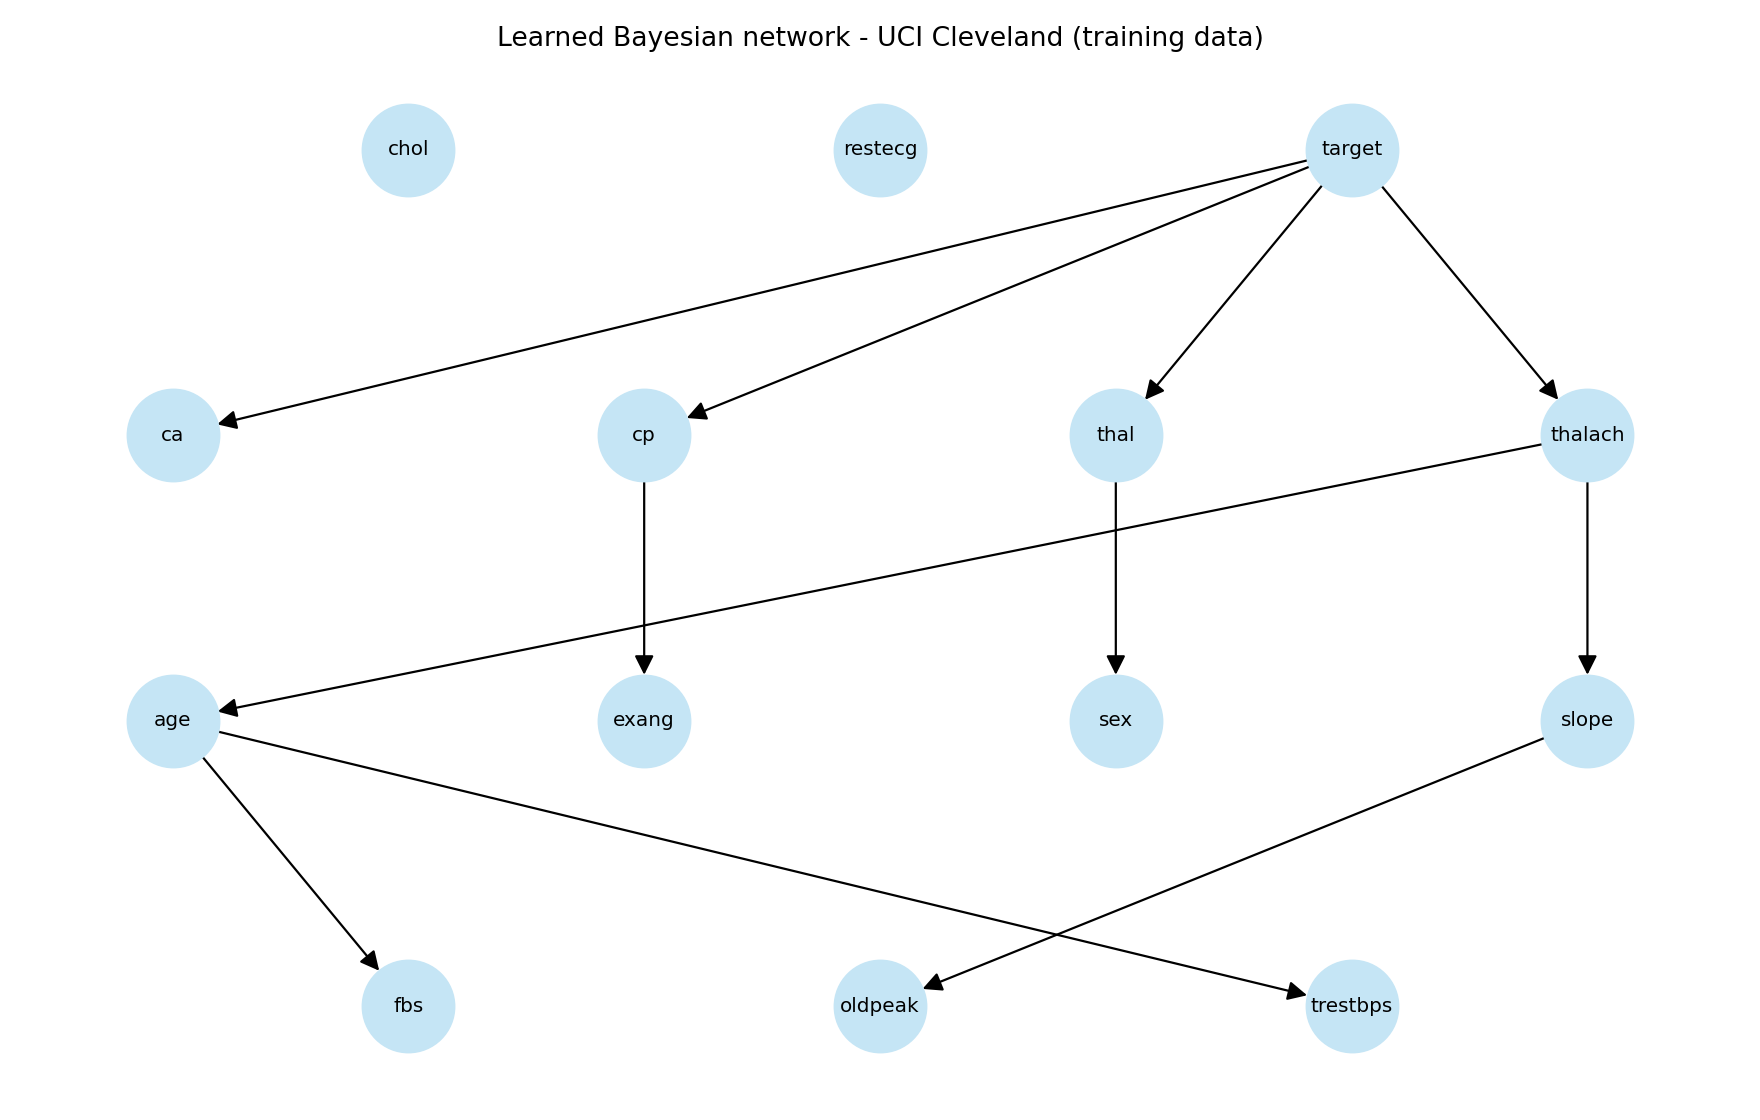

In [7]:
from IPython.display import Image, display
display(Image(filename=str(LAB_DIR / "results" / "heart_network.png")))

## 5. Clustering using EM and K-Means

**Aim:** Compare K-Means with a Gaussian mixture fitted by Expectation-Maximization.

**Method:** Exclude species and identifiers -> standardize four Iris features -> fit three clusters/components -> silhouette and adjusted Rand comparison -> plot and soft memberships.

**Corrections and notes:** Repairs the missing if/else, prevents target leakage and checks EM convergence. Cluster IDs are arbitrary. Plot shows two features; models use all four. Different metrics can favor different methods.

The following cell is the complete program from `05_em_kmeans.py`. Edit its configuration constants to use a compatible custom dataset.

In [8]:
"""Experiment 5: compare K-Means and EM-fitted Gaussian mixture clustering."""
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

BASE_DIR = Path(globals().get("__file__", "Computing_Lab1.ipynb")).resolve().parent
DATA_FILE = BASE_DIR / "data" / "iris.csv"
RESULTS_DIR = BASE_DIR / "results"
N_CLUSTERS = 3


def main():
    data = pd.read_csv(DATA_FILE)
    # Species is used only for the external evaluation, never for fitting.
    target = next((c for c in data if c.lower() in {"species", "variety", "class"}), None)
    labels = data[target] if target else None
    features = data.drop(columns=[c for c in data if c == target or c.lower() == "id"])
    X = features.apply(pd.to_numeric, errors="raise").to_numpy()
    if X.shape[1] < 2 or not np.isfinite(X).all():
        raise ValueError("Expected at least two complete numeric feature columns.")
    X_scaled = StandardScaler().fit_transform(X)
    kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=42)
    # GaussianMixture learns its parameters using Expectation-Maximization.
    gmm = GaussianMixture(n_components=N_CLUSTERS, covariance_type="full",
                          n_init=10, max_iter=500, reg_covar=1e-6, random_state=42)
    km_labels = kmeans.fit_predict(X_scaled)
    em_labels = gmm.fit_predict(X_scaled)
    if not gmm.converged_:
        raise RuntimeError("EM did not converge; increase max_iter or inspect the data.")
    scores = {}
    for name, clusters in [("K-Means", km_labels), ("EM (GMM)", em_labels)]:
        count = len(np.unique(clusters))
        if not 1 < count < len(X_scaled):
            raise ValueError("Silhouette requires 2 to n_samples-1 populated clusters.")
        scores[name] = silhouette_score(X_scaled, clusters)
        print(f"{name}: silhouette={scores[name]:.4f}; cluster counts={np.bincount(clusters)}")
        if labels is not None:
            print(f"  Adjusted Rand index vs species: {adjusted_rand_score(labels, clusters):.4f}")
    print(f"EM converged: {gmm.converged_}; iterations: {gmm.n_iter_}")
    print("Larger silhouette on this dataset:", max(scores, key=scores.get))
    print("This comparison does not establish that one method is always better.")
    print("First sample's EM membership probabilities:", gmm.predict_proba(X_scaled[:1])[0].round(4))

    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
    for ax, name, clusters, centers in zip(
        axes, ["K-Means", "EM (Gaussian mixture)"], [km_labels, em_labels],
        [kmeans.cluster_centers_, gmm.means_]
    ):
        ax.scatter(X_scaled[:, 0], X_scaled[:, 1], c=clusters, cmap="viridis", s=30)
        ax.scatter(centers[:, 0], centers[:, 1], color="#d43f3a", marker="X", s=150, label="Centers")
        ax.set_title(name)
        ax.set_xlabel(features.columns[0] + " (standardized)")
        ax.legend()
    axes[0].set_ylabel(features.columns[1] + " (standardized)")
    fig.suptitle("Iris: first two features shown; clustering uses all four")
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "clustering_comparison.png", dpi=160)
    plt.close(fig)
    pd.DataFrame({"kmeans": km_labels, "em_gmm": em_labels}).to_csv(
        RESULTS_DIR / "cluster_assignments.csv", index=False
    )
    return kmeans, gmm, X_scaled


if __name__ == "__main__":
    main()


K-Means: silhouette=0.4599; cluster counts=[53 50 47]
  Adjusted Rand index vs species: 0.6201
EM (GMM): silhouette=0.3742; cluster counts=[45 50 55]
  Adjusted Rand index vs species: 0.9039
EM converged: True; iterations: 19
Larger silhouette on this dataset: K-Means
This comparison does not establish that one method is always better.
First sample's EM membership probabilities: [0. 1. 0.]


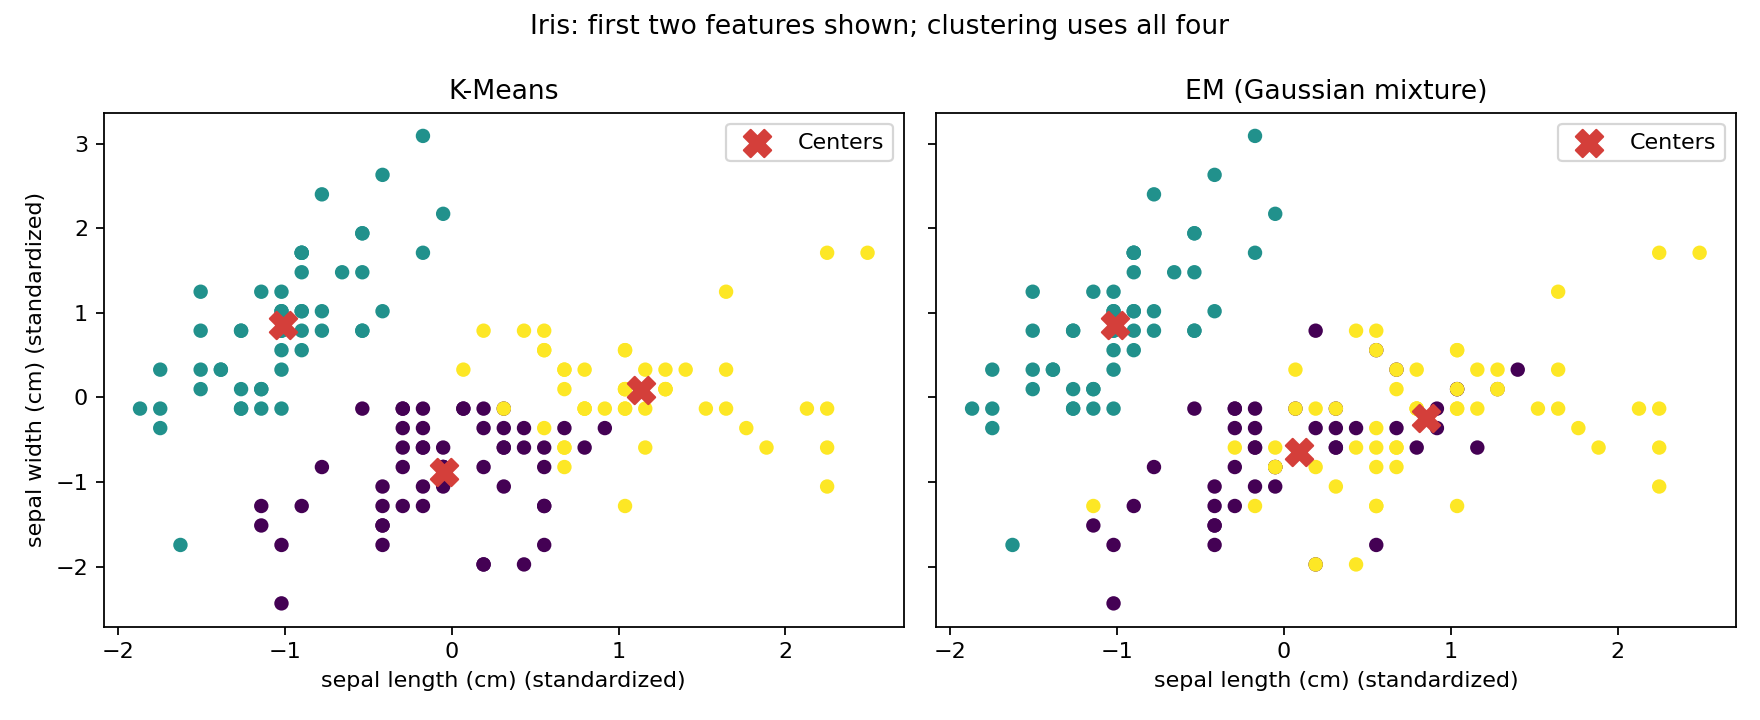

In [9]:
from IPython.display import Image, display
display(Image(filename=str(LAB_DIR / "results" / "clustering_comparison.png")))

## 6. K-nearest neighbors

**Aim:** Classify Iris using k=3 and list correct and incorrect held-out predictions.

**Method:** Stratified 60/40 split -> training-fitted StandardScaler pipeline -> KNN -> prediction details and accuracy.

**Corrections and notes:** Uses the scaler that was only imported in the reference and preserves row alignment. k is fixed before evaluation.

The following cell is the complete program from `06_knn.py`. Edit its configuration constants to use a compatible custom dataset.

In [10]:
"""Experiment 6: scaled KNN with correct and incorrect predictions."""
from pathlib import Path

import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

BASE_DIR = Path(globals().get("__file__", "Computing_Lab1.ipynb")).resolve().parent
DATA_FILE = BASE_DIR / "data" / "iris.csv"
K = 3


def main():
    data = pd.read_csv(DATA_FILE)
    target = next((c for c in data if c.lower() in {"species", "variety", "class"}), data.columns[-1])
    X = data.drop(columns=[c for c in data if c == target or c.lower() == "id"])
    X = X.apply(pd.to_numeric, errors="raise")
    y = data[target]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.4, random_state=42, stratify=y
    )
    # Scaling is fitted to the training data and reused unchanged on test data.
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=K))
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    comparison = X_test.copy()
    comparison["actual"] = y_test
    comparison["predicted"] = predictions
    comparison["correct"] = comparison["actual"] == comparison["predicted"]
    print(f"k={K} | train={len(X_train)}, test={len(X_test)}")
    for correct, title in [(True, "Correct predictions"), (False, "Incorrect predictions")]:
        subset = comparison[comparison["correct"] == correct]
        print(f"\n{title}: {len(subset)}")
        print(subset.to_string() if len(subset) else "None")
    print(f"\nAccuracy: {accuracy_score(y_test, predictions):.4f}")
    print("Confusion matrix, class order:", list(model.classes_))
    print(confusion_matrix(y_test, predictions, labels=model.classes_))
    out = BASE_DIR / "results"
    out.mkdir(parents=True, exist_ok=True)
    comparison.to_csv(out / "knn_predictions.csv", index_label="row")
    return model, comparison


if __name__ == "__main__":
    main()


k=3 | train=90, test=60

Correct predictions: 57
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)      actual   predicted  correct
40                 5.0               3.5                1.3               0.3      setosa      setosa     True
61                 5.9               3.0                4.2               1.5  versicolor  versicolor     True
18                 5.7               3.8                1.7               0.3      setosa      setosa     True
49                 5.0               3.3                1.4               0.2      setosa      setosa     True
20                 5.4               3.4                1.7               0.2      setosa      setosa     True
69                 5.6               2.5                3.9               1.1  versicolor  versicolor     True
93                 5.0               2.3                3.3               1.0  versicolor  versicolor     True
141                6.9               3.1                5.1    

## 7. Five-fold cross validation

**Aim:** Compare accuracy, macro precision, macro recall and macro F1 across five folds.

**Method:** Stratified shuffled folds -> a fresh entropy decision tree for each fold -> held-out metrics -> means and sample standard deviations.

**Corrections and notes:** Uses stratification and safe macro metrics; verifies each row is validated once. sklearn entropy CART is not the multiway ID3 algorithm from experiment 1.

The following cell is the complete program from `07_five_fold_cv.py`. Edit its configuration constants to use a compatible custom dataset.

In [11]:
"""Experiment 7: five stratified folds, with a fresh decision tree per fold."""
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier

BASE_DIR = Path(globals().get("__file__", "Computing_Lab1.ipynb")).resolve().parent
DATA_FILE = BASE_DIR / "data" / "iris.csv"


def main():
    data = pd.read_csv(DATA_FILE)
    target = next((c for c in data if c.lower() in {"species", "variety", "class"}), data.columns[-1])
    X = data.drop(columns=[c for c in data if c == target or c.lower() == "id"])
    X = X.apply(pd.to_numeric, errors="raise")
    y = data[target]
    if y.value_counts().min() < 5:
        raise ValueError("Each class needs at least five samples for five stratified folds.")
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    rows = []
    validation_count = np.zeros(len(data), dtype=int)
    for fold, (train_indices, test_indices) in enumerate(cv.split(X, y), start=1):
        # sklearn's entropy decision tree uses binary CART splits; it is not ID3.
        model = DecisionTreeClassifier(criterion="entropy", random_state=42)
        model.fit(X.iloc[train_indices], y.iloc[train_indices])
        predictions = model.predict(X.iloc[test_indices])
        actual = y.iloc[test_indices]
        validation_count[test_indices] += 1
        rows.append({
            "fold": fold, "accuracy": accuracy_score(actual, predictions),
            "precision_macro": precision_score(actual, predictions, average="macro", zero_division=0),
            "recall_macro": recall_score(actual, predictions, average="macro", zero_division=0),
            "f1_macro": f1_score(actual, predictions, average="macro", zero_division=0),
        })
    assert np.all(validation_count == 1), "Each row must be validated exactly once."
    scores = pd.DataFrame(rows).set_index("fold")
    print("Per-fold metrics (macro averaging gives each class equal weight):")
    print(scores.to_string(float_format=lambda value: f"{value:.4f}"))
    summary = pd.DataFrame({"mean": scores.mean(), "sample_std": scores.std(ddof=1)})
    print("\nSummary across five folds:")
    print(summary.to_string(float_format=lambda value: f"{value:.4f}"))
    out = BASE_DIR / "results"
    out.mkdir(parents=True, exist_ok=True)
    scores.to_csv(out / "five_fold_scores.csv")
    summary.to_csv(out / "five_fold_summary.csv")
    return scores, validation_count


if __name__ == "__main__":
    main()


Per-fold metrics (macro averaging gives each class equal weight):
      accuracy  precision_macro  recall_macro  f1_macro
fold                                                   
1       1.0000           1.0000        1.0000    1.0000
2       0.9667           0.9697        0.9667    0.9666
3       0.9333           0.9444        0.9333    0.9327
4       0.9667           0.9697        0.9667    0.9666
5       0.9000           0.9024        0.9000    0.8997

Summary across five folds:
                  mean  sample_std
accuracy        0.9533      0.0380
precision_macro 0.9572      0.0365
recall_macro    0.9533      0.0380
f1_macro        0.9531      0.0382


## 8. Familiarization of Google Colab

**Aim:** Practice Python cells, libraries, CSV files, plots and a small ML workflow.

**Method:** Inspect runtime -> NumPy and pandas -> save/reload CSV -> plot -> train/test Iris classifier -> save outputs.

**Corrections and notes:** Adds executable demonstrations to the reference theory. Fixed GPU models, quotas and runtime durations are not guaranteed. See the official Colab FAQ linked below.

The following cell is the complete program from `08_google_colab.py`. Edit its configuration constants to use a compatible custom dataset.

In [12]:
"""Experiment 8: Python, NumPy, pandas, plots, files and ML in Google Colab.

This script also runs locally. Colab-only upload/Drive/download examples are in
the notebook's final section and are optional interactive steps.
"""
import platform
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

BASE_DIR = Path(globals().get("__file__", "Computing_Lab1.ipynb")).resolve().parent


def main():
    print("Python:", platform.python_version())
    print("Operating system:", platform.system())
    print("Hello, Google Colab!")
    matrix = np.array([[1, 2], [3, 4]])
    print("\nNumPy matrix:\n", matrix)
    print("Matrix product A @ A:\n", matrix @ matrix)
    frame = pd.DataFrame({"student": ["A", "B", "C"], "marks": [78, 85, 92]})
    print("\npandas DataFrame:\n", frame.to_string(index=False))
    print("Mean mark:", frame["marks"].mean())
    out = BASE_DIR / "results"
    out.mkdir(parents=True, exist_ok=True)
    frame.to_csv(out / "colab_demo.csv", index=False)
    reloaded = pd.read_csv(out / "colab_demo.csv")
    print("CSV saved and read back:", reloaded.equals(frame))
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(frame["student"], frame["marks"], color="#277da1")
    ax.set(xlabel="Student", ylabel="Marks", title="Google Colab: plotting example", ylim=(0, 100))
    fig.tight_layout()
    fig.savefig(out / "colab_demo.png", dpi=160)
    plt.close(fig)

    dataset = load_iris()
    X_train, X_test, y_train, y_test = train_test_split(
        dataset.data, dataset.target, test_size=0.2, random_state=42, stratify=dataset.target
    )
    start = perf_counter()
    model = GaussianNB().fit(X_train, y_train)
    print(f"\nIris test accuracy: {accuracy_score(y_test, model.predict(X_test)):.4f}")
    print(f"Fit and prediction time: {perf_counter() - start:.4f} seconds (machine-dependent)")
    print("Results saved in:", out)
    print("These experiments run on a CPU; a GPU is not required.")


if __name__ == "__main__":
    main()


Python: 3.12.14
Operating system: Darwin
Hello, Google Colab!

NumPy matrix:
 [[1 2]
 [3 4]]
Matrix product A @ A:
 [[ 7 10]
 [15 22]]

pandas DataFrame:
 student  marks
      A     78
      B     85
      C     92
Mean mark: 85.0
CSV saved and read back: True

Iris test accuracy: 0.9667
Fit and prediction time: 0.0003 seconds (machine-dependent)
Results saved in: /Users/suhathalib/Documents/ChatGPT/Mtech/tmp/computing_lab_review/notebook_run/computing_lab1_workspace/results
These experiments run on a CPU; a GPU is not required.


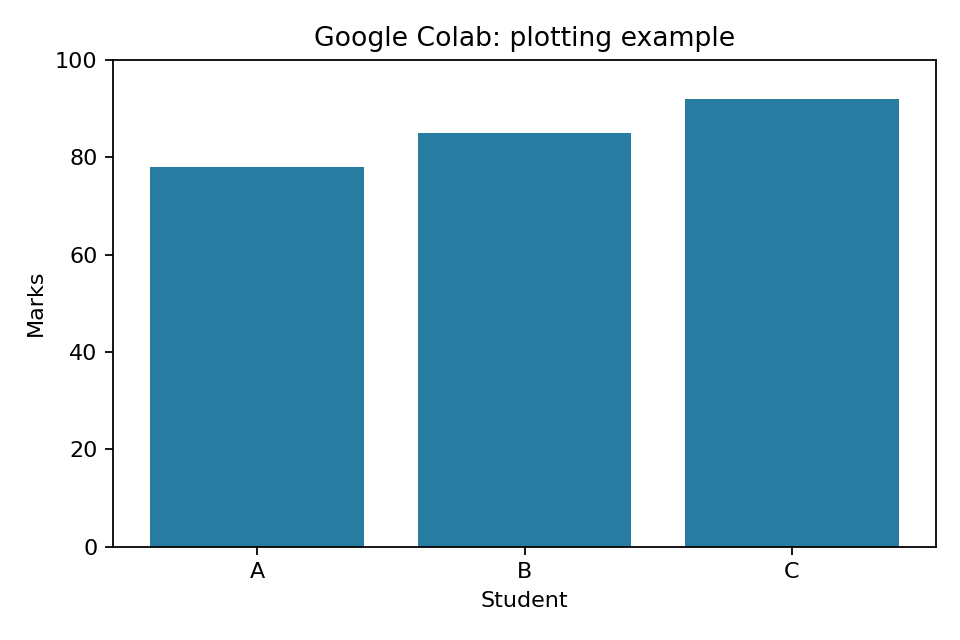

In [13]:
from IPython.display import Image, display
display(Image(filename=str(LAB_DIR / "results" / "colab_demo.png")))

### Optional: inspect accelerators

These labs run on a CPU. If your Colab runtime has an NVIDIA GPU, the following cell displays its status; otherwise it prints a message. Accelerator allocation and runtime limits vary, as described in the [official Colab FAQ](https://research.google.com/colaboratory/faq.html).

In [14]:
import shutil
import subprocess

if shutil.which("nvidia-smi"):
    subprocess.run(["nvidia-smi"], check=False)
else:
    print("No NVIDIA GPU utility found. CPU execution is sufficient for these labs.")

No NVIDIA GPU utility found. CPU execution is sufficient for these labs.


### Optional: upload a custom CSV

Set the flag to `True` and run the cell in Colab to choose a file. Uploaded files are placed in the working folder. Set the appropriate experiment's `DATA_FILE` or `DATA_FILES` to its path in that experiment's code cell. Ensure the schema and target coding match the program's documented contract before running it.

In [15]:
UPLOAD_A_FILE = False
if UPLOAD_A_FILE:
    from google.colab import files
    uploaded = files.upload()
    print("Uploaded:", list(uploaded))
else:
    print("Upload skipped. Set UPLOAD_A_FILE=True to open the Colab file picker.")

Upload skipped. Set UPLOAD_A_FILE=True to open the Colab file picker.


### Optional: mount Google Drive and retain a result

Set the flag to `True` in Colab and complete Google's authorization prompt. This example copies the small demonstration CSV to your Drive. Notebook sharing does not automatically share your runtime files. Runtime storage is temporary; save results you need to keep.

In [16]:
MOUNT_GOOGLE_DRIVE = False
if MOUNT_GOOGLE_DRIVE:
    from google.colab import drive
    import shutil
    drive.mount("/content/drive")
    destination = Path("/content/drive/MyDrive/Computing_Lab1_results")
    destination.mkdir(parents=True, exist_ok=True)
    shutil.copy2(LAB_DIR / "results" / "colab_demo.csv", destination / "colab_demo.csv")
    print("Saved demo CSV to:", destination)
else:
    print("Drive access skipped. Set MOUNT_GOOGLE_DRIVE=True to authorize access.")

Drive access skipped. Set MOUNT_GOOGLE_DRIVE=True to authorize access.


### Optional: download experiment results

Set the flag to `True` in Colab to create and download a ZIP of the current results. Save the notebook separately using its File menu. In Jupyter on your own computer, the `results` folder is already on local disk.

In [17]:
DOWNLOAD_RESULTS = False
if DOWNLOAD_RESULTS:
    from google.colab import files
    import shutil
    archive_path = shutil.make_archive(str(LAB_DIR / "Computing_Lab1_results"), "zip", LAB_DIR / "results")
    files.download(archive_path)
else:
    print("Download skipped. Set DOWNLOAD_RESULTS=True to download your results.")

Download skipped. Set DOWNLOAD_RESULTS=True to download your results.


## Results and references

The example outputs depend on the included datasets, random splits and package versions. They need not match PDF screenshots whose original CSVs were not attached. Timing and platform information vary by runtime.

- [Google Colab FAQ](https://research.google.com/colaboratory/faq.html)
- [scikit-learn Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html)
- [scikit-learn toy datasets](https://scikit-learn.org/stable/datasets/toy_dataset.html)
- [pgmpy 1.0.0 hill-climb API](https://pgmpy.org/_modules/pgmpy/estimators/HillClimbSearch.html)
- UCI Heart Disease: Janosi, Steinbrunn, Pfisterer and Detrano (1988), [DOI 10.24432/C52P4X](https://doi.org/10.24432/C52P4X)
- UCI SMS Spam Collection: Almeida and Hidalgo (2011), [DOI 10.24432/C5CC84](https://doi.org/10.24432/C5CC84)

Full corrections, dataset coding, original credits, checksums and local execution instructions accompany the ZIP package in `README.md` and `data/SOURCES.md`.